In [3]:
# =========================
# Librerias
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import style
from scipy import signal
from scipy.signal import find_peaks, savgol_filter



In [2]:
# =========================
# Funciones útiles
# =========================
def obtener_diferencia(t, ch1, ch2, temp, Ts):

    diferencias = []

    K = 0

    while True:

        # Tiempo en CH1 que queremos utilizar
        t_ref = temp[0] + Ts * K

        if t_ref > temp[1]:
            break

        # Valor de CH1 en ese instante
        valor_ref = np.interp(t_ref, t, ch1)

        # Buscamos solamente desde t_ref hacia adelante
        inicio = np.searchsorted(t, t_ref)

        # Diferencia CH2 - valor de CH1
        d = ch2[inicio:] - valor_ref

        # Buscar el primer cambio de signo
        cruces = np.where(d[:-1] * d[1:] <= 0)[0]

        if len(cruces) == 0:

            diferencias.append(np.nan)

        else:

            i = cruces[0] + inicio

            # Interpolación del cruce
            t1 = t[i]
            t2 = t[i + 1]

            y1 = ch2[i] - valor_ref
            y2 = ch2[i + 1] - valor_ref

            tx = t1 - y1 * (t2 - t1) / (y2 - y1)

            diferencias.append(tx - t_ref)

        K += 1

    return np.array(diferencias)

#-----------------------------------------------------------------------------------------------------------------
def obtener_diferencia_2t(t1, ch1, t2, ch2, temp, Ts):

    diferencias = []
    K = 0

    while True:

        # Instantes de referencia del canal 1
        t_ref = temp[0] + Ts * K

        if t_ref > temp[1]:
            break

        # Valor de CH1 en ese instante
        valor_ref = np.interp(t_ref, t1, ch1)

        # Solo consideramos CH2 desde t_ref en adelante
        inicio = np.searchsorted(t2, t_ref)

        d = ch2[inicio:] - valor_ref

        # Buscar el primer cambio de signo
        cruces = np.where(d[:-1] * d[1:] <= 0)[0]

        if len(cruces) == 0:
            diferencias.append(np.nan)

        else:
            i = cruces[0] + inicio

            t_a = t2[i]
            t_b = t2[i + 1]

            y_a = ch2[i] - valor_ref
            y_b = ch2[i + 1] - valor_ref

            # Interpolación del cruce
            if y_b != y_a:
                t_cruce = t_a - y_a * (t_b - t_a) / (y_b - y_a)
                diferencias.append(t_cruce - t_ref)
            else:
                diferencias.append(np.nan)

        K += 1

    return np.array(diferencias)

    
#-----------------------------------------------------------------------------------------------------------------
# Función para mostrar en formato de ingenieria las unidades
def eng_format(value, unit=""):
    import numpy as np
    if value == 0:
        return f"0 {unit}"
    exp = int(np.floor(np.log10(np.abs(value)) / 3) * 3)
    scaled = value / (10**exp)
    prefixes = {-12: "p",-9: "n",-6: "u",-3: "m",0: "",3: "k",6: "M",9: "G"}
    prefix = prefixes.get(exp, f"e{exp}")
    return f"{scaled:.2f} {prefix}{unit}"

In [12]:
# =========================
# CSV
# =========================
data=np.genfromtxt('SDSTEST.csv',delimiter=',', skip_header=3)



# =========================
# Analisis
# =========================
# 1. Cargar las columnas de datos
# Las columnas 0 a 2 contienen metadatos del osciloscopio;
# las columnas 3, 4 y 5 contienen el tiempo y las lecturas de CH1 y CH2.
df = pd.read_csv(
    'SDSTEST.csv',
    skiprows=2,
    usecols=[3, 4, 5],
    names=['Time_raw', 'CH1_V', 'CH2_V'],
    dtype=float,
)

# 2. Reconstruir la escala de tiempo continua
# El osciloscopio muestrea a dt = 2 µs (0.000002 s) desde t = -1.4 s hasta +1.4 s
dt = 2e-6
t_inicio = -1.4
tiempo = t_inicio + np.arange(len(df)) * dt

# 3. Factor de submuestreo para optimizar la visualización
# Muestra 1 de cada 50 puntos (~28.000 puntos) para graficar rápido sin perder fidelidad
sub = 50

# =========================
# Filtrado
# =========================
ch1 = signal.savgol_filter(df['CH1_V'].iloc[::sub], 191, 6) 
ch2 = signal.savgol_filter(df['CH2_V'].iloc[::sub], 191, 6)
t = tiempo[::sub]


delta_t = obtener_diferencia( t, ch1, ch2*0.2/0.05, temp=[0.42, 0.6], Ts=0.01 )
delta_t_promedio = np.mean(delta_t)

print(r'Promedio del desfasaje temporal entre las dos señales=', eng_format(delta_t_promedio, 's'))


Promedio del desfasaje temporal entre las dos señales= 35.09 ms


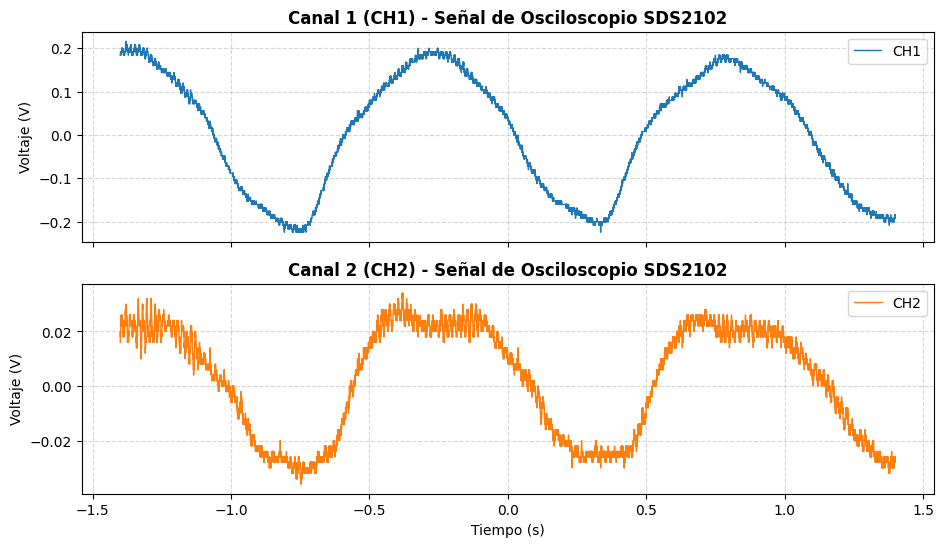

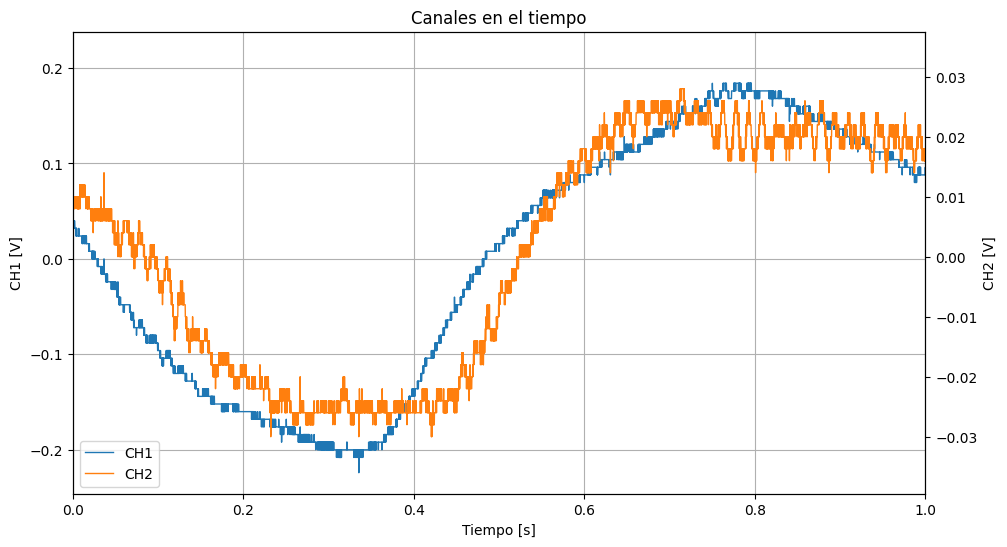

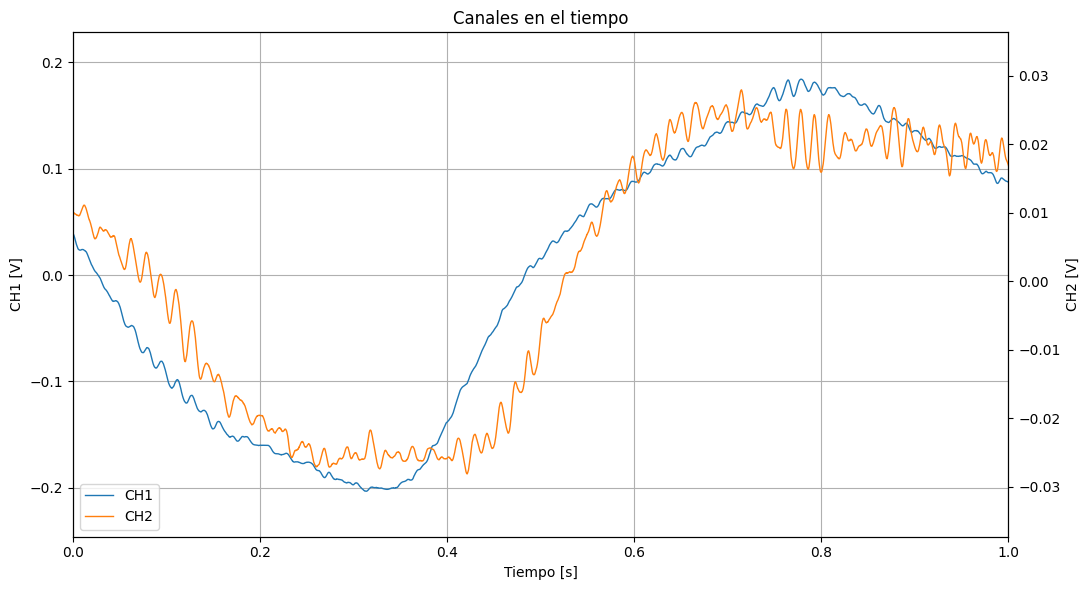

In [13]:
# =========================
# Ploteo 1
# =========================
# 4. Crear los gráficos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

# Canal 1
ax1.plot(
    tiempo[::sub],
    df['CH1_V'].iloc[::sub],
    color='#1f77b4',
    linewidth=1,
    label='CH1',
)
ax1.set_title(
    'Canal 1 (CH1) - Señal de Osciloscopio SDS2102',
    fontsize=12,
    fontweight='bold',
)
ax1.set_ylabel('Voltaje (V)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper right')

# Canal 2
ax2.plot(
    tiempo[::sub],
    df['CH2_V'].iloc[::sub],
    color='#ff7f0e',
    linewidth=1,
    label='CH2',
)
ax2.set_title(
    'Canal 2 (CH2) - Señal de Osciloscopio SDS2102',
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Tiempo (s)', fontsize=10)
ax2.set_ylabel('Voltaje (V)', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')



# =========================
# Ploteo 2
# =========================
fig1, ax3 = plt.subplots(figsize=(11, 6))

# CH1
ax3.plot(
    tiempo[::sub],
    df['CH1_V'].iloc[::sub],
    color='#1f77b4',
    linewidth=1,
    label='CH1',
)
ax3.set_ylabel('CH1 [V]')
ax3.set_xlabel('Tiempo [s]')
ax3.set_xlim(0, 1)
ax3.grid()

# CH2
ax4 = ax3.twinx()
ax4.plot(
    tiempo[::sub],
    df['CH2_V'].iloc[::sub],
    color='#ff7f0e',
    linewidth=1,
    label='CH2',
)
ax4.set_ylabel('CH2 [V]')

# Leyenda combinada y título
lineas1, etiquetas1 = ax3.get_legend_handles_labels()
lineas2, etiquetas2 = ax4.get_legend_handles_labels()
ax3.legend(
    lineas1 + lineas2,
    etiquetas1 + etiquetas2,
    loc='lower left'
)
ax3.set_title('Canales en el tiempo')



# =========================
# Ploteo 3
# =========================
fig1, ax5 = plt.subplots(figsize=(11, 6))

# CH1
ax5.plot(
    t,
    ch1,
    color='#1f77b4',
    linewidth=1,
    label='CH1',
)
ax5.set_ylabel('CH1 [V]')
ax5.set_xlabel('Tiempo [s]')
ax5.set_xlim(0, 1)
ax5.grid()

# CH2
ax6 = ax5.twinx()
ax6.plot(
    t,
    ch2,
    color='#ff7f0e',
    linewidth=1,
    label='CH2',
)
ax6.set_ylabel('CH2 [V]')

# Leyenda combinada y título
lineas1, etiquetas1 = ax5.get_legend_handles_labels()
lineas2, etiquetas2 = ax6.get_legend_handles_labels()
ax5.legend(
    lineas1 + lineas2,
    etiquetas1 + etiquetas2,
    loc='lower left'
)
ax5.set_title('Canales en el tiempo')

plt.tight_layout()
plt.show()

------------------------------------------------------------------------------
♦ Frecuencia de pico mayor FFT: 5.714 Hz
♦ Fase del CH1 para la frecuencia del máximo: -75.25°
♦ Fase del CH2 para la frecuencia del máximo: 97.31°
El desfasaje temporal entre las dos señales por FFT es de:
 =>	Tao_FFT = 130.17 ms
------------------------------------------------------------------------------
El desfasaje temporal entre las dos señales por Correlación Cruzada es de:
 =>	Tao_correlate = 102.50 ms
------------------------------------------------------------------------------


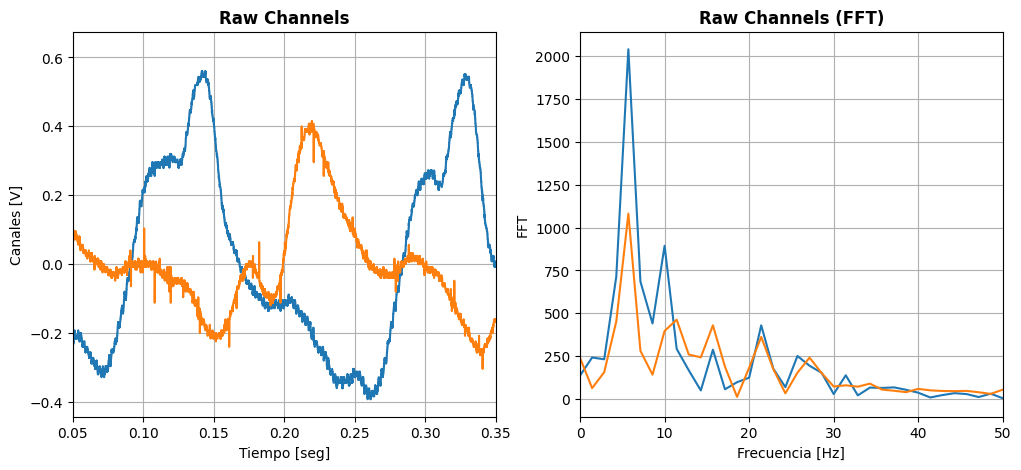

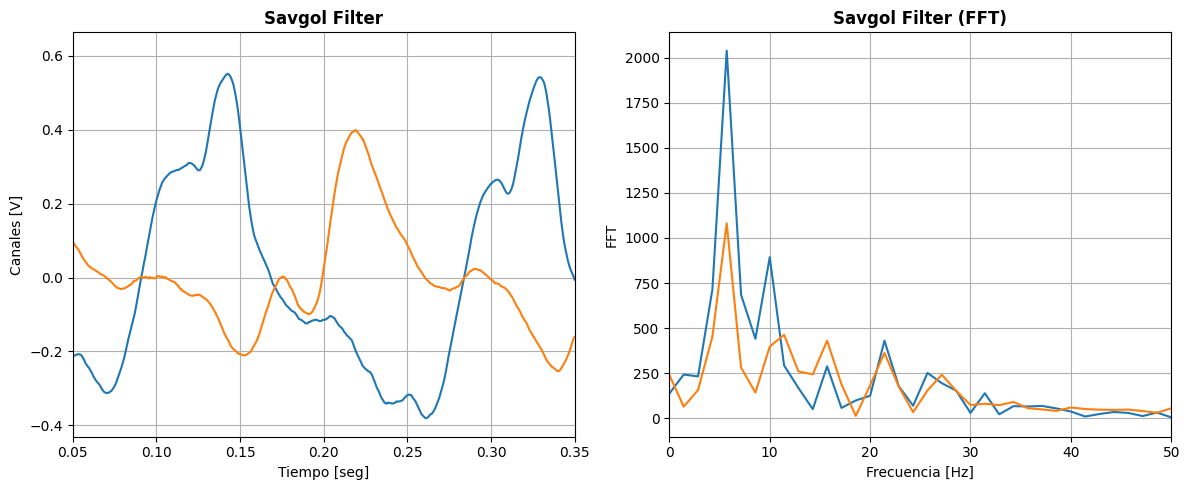

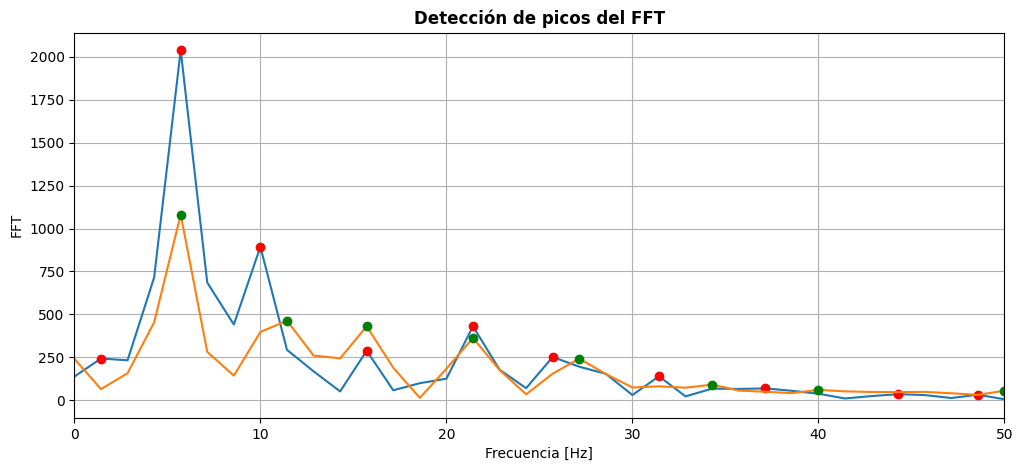

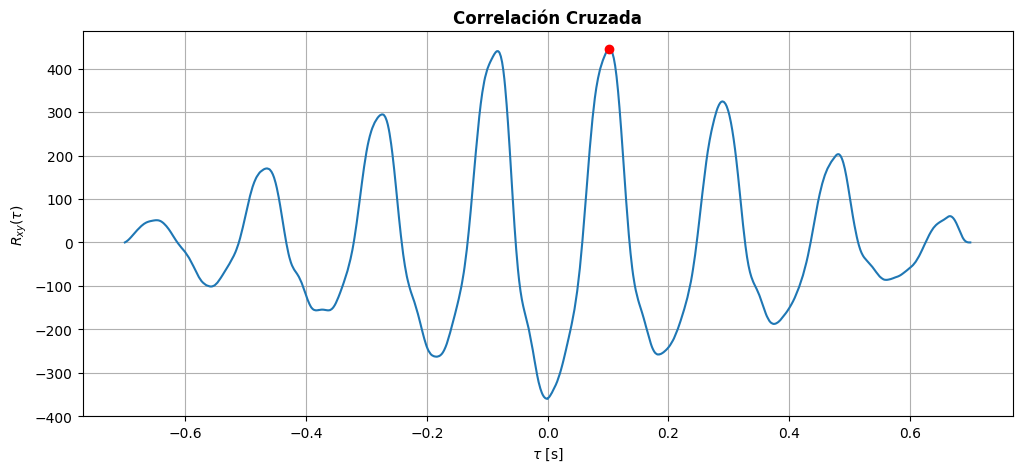

In [19]:
# ===============================
# CSV
# ===============================

df = pd.read_csv(
    'end.csv',
    skiprows=2,
    usecols=[3, 4, 5],
    names=['Time', 'CH1', 'CH2'],
    dtype=float,
)
t = df['Time']              #  Permite saltearte puntos y así grafica menos ruidoso: "df['Time_raw'].iloc[::sub]"
Ts = np.mean(np.diff(t))    # Período de muestreo
Fs = 1/Ts                   # Frecuencia de muestreo



# ===============================
# Filtrado
# ===============================

ch1 = signal.savgol_filter(df['CH1'], 191, 6) 
ch2 = signal.savgol_filter(df['CH2'], 191, 6)



# ===============================
# Analisis: FFT
# ===============================

f_max = 5.71428571                 # Se setea la frecuencia donde se encuentra el máximo de la FFT conseguido más adelante

f = np.fft.rfftfreq( len(t) , Ts ) # Eje frecuencial de la FFT

# Detectamos los picos de la FFT de ambos canales
picos_ch1, propiedades_ch1 = find_peaks(
    np.abs( np.fft.rfft(df['CH1']) ),
    prominence=10,
)
picos_ch2, propiedades_ch2 = find_peaks(
    np.abs( np.fft.rfft(df['CH2']) ),
    prominence=10,
)
    # Parámetros útiles
        # prominence: prominencia mínima del pico. Sirve para ignorar pequeñas fluctuaciones respecto del entorno.
        # height: altura mínima del pico.
        # distance: distancia mínima entre picos, expresada en muestras del espectro.
        # width: ancho mínimo del pico, también en muestras.

# Se calcula la fase de la FFt de ambas señales
fase_ch1 = np.angle( np.fft.rfft(df['CH1']) , deg=True )
fase_ch2 = np.angle( np.fft.rfft(df['CH2']) , deg=True )
idx = np.argmin(np.abs(f - f_max))                        # Busca el índice de la frecuencia disponible más cercana a 5.714 Hz.

# Calculo del desfase temporal de la FFT:
#    tao = T * ang(f_max)/360°
tao_ch1 = 1/idx * ( fase_ch1[idx] + 360 )/360
tao_ch2 = 1/idx * fase_ch2[idx]/360

Desfasaje_temporal_FFT = tao_ch1 - tao_ch2



# ===============================
# Analisis: Correlación Cruzada
# ===============================

x = df['CH1'].to_numpy()  # Entrada
y = df['CH2'].to_numpy()  # Salida

Rxy = signal.correlate( y - np.mean(y) , x - np.mean(x) , mode='full' )
lags = signal.correlation_lags(len(y), len(x), mode='full')
tao = lags / Fs

idx_correlate = np.argmax(Rxy)

Desfasaje_temporal_correlate = tao[ idx_correlate ]



# ===============================
# Printeo
# ===============================

print('------------------------------------------------------------------------------')
print(f"♦ Frecuencia de pico mayor FFT: {f[idx]:.3f} Hz")
print(f"♦ Fase del CH1 para la frecuencia del máximo: {fase_ch1[idx]:.2f}°")
print(f"♦ Fase del CH2 para la frecuencia del máximo: {fase_ch2[idx]:.2f}°")


print(f"El desfasaje temporal entre las dos señales por FFT es de:\n",
f"=>\tTao_FFT = {eng_format(Desfasaje_temporal_FFT, 's')}")

print('------------------------------------------------------------------------------')
print(f"El desfasaje temporal entre las dos señales por Correlación Cruzada es de:\n",
f"=>\tTao_correlate = {eng_format(Desfasaje_temporal_correlate, 's')}")

print('------------------------------------------------------------------------------')



# ===============================
# Ploteo
# ===============================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot( t , df['CH2'] ) # CH2 azul primera 
ax1.plot( t , df['CH1'] )
ax1.set_title('Raw Channels', fontsize=12, fontweight='bold')
ax1.set_xlabel('Tiempo [seg]')
ax1.set_ylabel('Canales [V]')
ax1.grid()
ax1.set_xlim(0.05,0.35)

ax2.plot(f, np.abs( np.fft.rfft(df['CH2']) ) )
ax2.plot(f, np.abs( np.fft.rfft(df['CH1']) ) )
ax2.set_title('Raw Channels (FFT)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_ylabel('FFT')
ax2.grid()
ax2.set_xlim(0 , 50)

    # ---------------------------------------------------------------- 

fig, (ax3, ax4) = plt.subplots(1, 2, figsize=(12, 5))

ax3.plot( t , ch2 ) # CH2 azul primera 
ax3.plot( t , ch1 )
ax3.set_title('Savgol Filter', fontsize=12, fontweight='bold')
ax3.set_xlabel('Tiempo [seg]')
ax3.set_ylabel('Canales [V]')
ax3.grid()
ax3.set_xlim(0.05,0.35)

ax4.plot(f, np.abs( np.fft.rfft(ch2) ) )
ax4.plot(f, np.abs( np.fft.rfft(ch1) ) )
ax4.set_title('Savgol Filter (FFT)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Frecuencia [Hz]')
ax4.set_ylabel('FFT')
ax4.grid()
ax4.set_xlim(0 , 50)

plt.tight_layout()
plt.show()

    # ----------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(f, np.abs( np.fft.rfft(df['CH2']) ))
plt.plot(f[picos_ch2], np.abs( np.fft.rfft(df['CH2']) )[picos_ch2], 'ro')

plt.plot(f, np.abs( np.fft.rfft(df['CH1']) ))
plt.plot(f[picos_ch1], np.abs( np.fft.rfft(df['CH1']) )[picos_ch1], 'go')
plt.title('Detección de picos del FFT', fontsize=12, fontweight='bold')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('FFT')
plt.grid()
plt.xlim(0, 50)

    # ----------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot( tao , Rxy )
plt.plot(tao[idx_correlate], Rxy[idx_correlate], 'ro')

plt.title('Correlación Cruzada', fontsize=12, fontweight='bold')
plt.xlabel(r'$\tau$ [s]')
plt.ylabel(r'$R_{xy}(\tau)$')
plt.grid()

plt.show()


